In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [6]:
files = [
    "../data/prices_round_1_day_-2.csv",
    "../data/prices_round_1_day_-1.csv",
    "../data/prices_round_1_day_0.csv",
]

datasets = {}

for file in files:
    df = pd.read_csv(file, sep=";")
    day = df["day"].iloc[0]
    datasets[day] = df


PRODUCT INTARIAN_PEPPER_ROOT | DAY -2
count     9984.000000
mean     10499.963542
std        288.722378
min       9998.500000
25%      10250.000000
50%      10500.000000
75%      10750.000000
max      11003.000000
Name: mid_price, dtype: float64


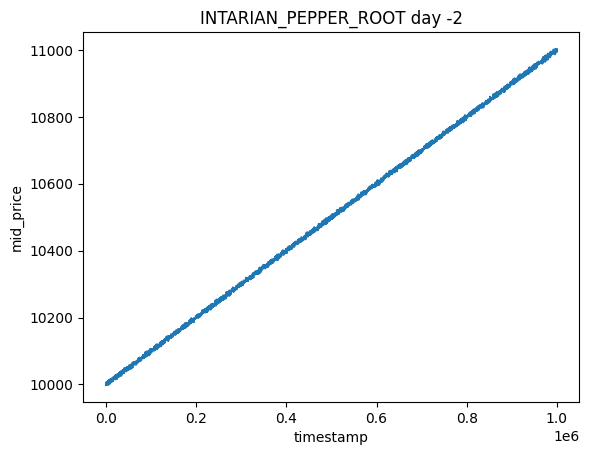


PRODUCT INTARIAN_PEPPER_ROOT | DAY -1
count     9983.000000
mean     11500.030051
std        288.669011
min      10995.000000
25%      11250.750000
50%      11500.000000
75%      11750.000000
max      12006.000000
Name: mid_price, dtype: float64


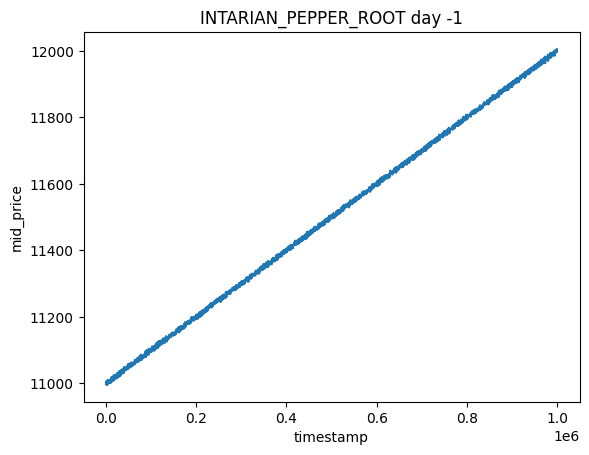


PRODUCT INTARIAN_PEPPER_ROOT | DAY 0
count     9979.000000
mean     12500.173013
std        288.730986
min      11994.000000
25%      12250.000000
50%      12500.000000
75%      12750.500000
max      13007.000000
Name: mid_price, dtype: float64


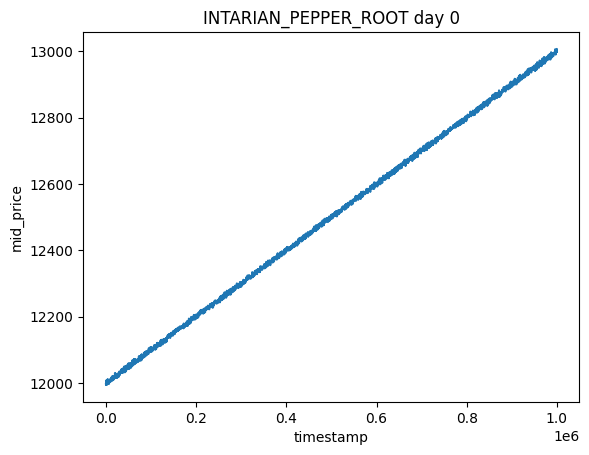

In [7]:
products = ["INTARIAN_PEPPER_ROOT"]

for product in products:
    for day, df in datasets.items():
        df_p = df[df["product"] == product].copy()
        df_p = df_p[df_p["mid_price"] > 0]

        print(f"\nPRODUCT {product} | DAY {day}")
        print(df_p["mid_price"].describe())

        plt.figure()
        plt.plot(df_p["timestamp"], df_p["mid_price"])
        plt.title(f"{product} day {day}")
        plt.xlabel("timestamp")
        plt.ylabel("mid_price")
        plt.show()

In [8]:
summary_rows = []

for product in products:
    for day, df in datasets.items():
        df_p = df[df["product"] == product].copy()
        df_p = df_p[df_p["mid_price"] > 0]

        summary_rows.append({
            "product": product,
            "day": day,
            "count": df_p["mid_price"].count(),
            "mean": df_p["mid_price"].mean(),
            "median": df_p["mid_price"].median(),
            "std": df_p["mid_price"].std(),
            "min": df_p["mid_price"].min(),
            "max": df_p["mid_price"].max(),
        })

summary_df = pd.DataFrame(summary_rows).sort_values(["product", "day"])
summary_df

,product,day,count,mean,median,std,min,max
0,INTARIAN_PEPPER_ROOT,-2,9984,10499.963542,10500.0,288.722378,9998.5,11003.0
1,INTARIAN_PEPPER_ROOT,-1,9983,11500.030051,11500.0,288.669011,10995.0,12006.0
2,INTARIAN_PEPPER_ROOT,0,9979,12500.173013,12500.0,288.730986,11994.0,13007.0


## PEPPER linear-uptrend diagnostics
Use these metrics to quantify trend strength, stability, and how much exploitable noise remains around the trend line.

In [12]:
diag_rows = []
day_series = {}
fit_series = {}
resid_series = {}
segment_rows = []

for day, df in datasets.items():
    df_p = df[df["product"] == "INTARIAN_PEPPER_ROOT"].copy()
    df_p = df_p[df_p["mid_price"] > 0].sort_values("timestamp").copy()
    if len(df_p) < 5:
        continue

    t = df_p["timestamp"].to_numpy(dtype=float)
    y = df_p["mid_price"].to_numpy(dtype=float)

    slope, intercept = np.polyfit(t, y, deg=1)
    y_hat = slope * t + intercept
    resid = y - y_hat

    ss_res = float(np.sum((y - y_hat) ** 2))
    ss_tot = float(np.sum((y - np.mean(y)) ** 2))
    r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan

    dy = np.diff(y)
    returns = np.diff(np.log(y)) if np.all(y > 0) else np.array([])

    # Segment slope stability: split day into 10 equal index chunks and estimate slope per chunk.
    segment_slopes = []
    for seg_idx in np.array_split(df_p.index.to_numpy(), 10):
        seg = df_p.loc[seg_idx]
        if len(seg) >= 3:
            seg_t = seg["timestamp"].to_numpy(dtype=float)
            seg_y = seg["mid_price"].to_numpy(dtype=float)
            seg_slope = np.polyfit(seg_t, seg_y, deg=1)[0]
            segment_slopes.append(float(seg_slope))

    seg_mean = float(np.mean(segment_slopes)) if segment_slopes else np.nan
    seg_std = float(np.std(segment_slopes)) if segment_slopes else np.nan
    seg_cv = seg_std / abs(seg_mean) if segment_slopes and abs(seg_mean) > 1e-12 else np.nan

    resid_std = float(np.std(resid))
    resid_mad = float(np.median(np.abs(resid - np.median(resid))))
    resid_q95 = float(np.quantile(np.abs(resid), 0.95))

    if resid_std > 1e-12:
        resid_z = resid / resid_std
        outlier_2sigma_rate = float(np.mean(np.abs(resid_z) > 2.0))
        outlier_3sigma_rate = float(np.mean(np.abs(resid_z) > 3.0))
    else:
        outlier_2sigma_rate = np.nan
        outlier_3sigma_rate = np.nan

    diag_rows.append({
        "day": int(day),
        "n": int(len(df_p)),
        "start_price": float(y[0]),
        "end_price": float(y[-1]),
        "day_change": float(y[-1] - y[0]),
        "slope_price_per_ts": float(slope),
        "slope_price_per_10k_ts": float(slope * 10_000),
        "r2_linear": float(r2),
        "rmse_resid": float(np.sqrt(np.mean(resid**2))),
        "resid_std": resid_std,
        "resid_mad": resid_mad,
        "resid_abs_q95": resid_q95,
        "resid_autocorr_lag1": float(pd.Series(resid).autocorr(lag=1)),
        "resid_autocorr_lag5": float(pd.Series(resid).autocorr(lag=5)),
        "positive_step_ratio": float(np.mean(dy > 0)) if len(dy) else np.nan,
        "negative_step_ratio": float(np.mean(dy < 0)) if len(dy) else np.nan,
        "flat_step_ratio": float(np.mean(dy == 0)) if len(dy) else np.nan,
        "step_std": float(np.std(dy)) if len(dy) else np.nan,
        "step_autocorr_lag1": float(pd.Series(dy).autocorr(lag=1)) if len(dy) > 1 else np.nan,
        "logret_mean": float(np.mean(returns)) if len(returns) else np.nan,
        "logret_std": float(np.std(returns)) if len(returns) else np.nan,
        "logret_autocorr_lag1": float(pd.Series(returns).autocorr(lag=1)) if len(returns) > 1 else np.nan,
        "segment_slope_mean": seg_mean,
        "segment_slope_std": seg_std,
        "segment_slope_cv": seg_cv,
        "outlier_2sigma_rate": outlier_2sigma_rate,
        "outlier_3sigma_rate": outlier_3sigma_rate,
    })

    for idx, s in enumerate(segment_slopes):
        segment_rows.append({"day": int(day), "segment": idx, "segment_slope": s})

    day_series[day] = df_p
    fit_series[day] = y_hat
    resid_series[day] = resid

pepper_diag_df = pd.DataFrame(diag_rows).sort_values("day").reset_index(drop=True)
pepper_segment_df = pd.DataFrame(segment_rows)

# Day-to-day shift diagnostics (close->next open gap).
if len(pepper_diag_df) >= 2:
    pepper_diag_df["next_day_open"] = pepper_diag_df["start_price"].shift(-1)
    pepper_diag_df["close_to_next_open_gap"] = pepper_diag_df["next_day_open"] - pepper_diag_df["end_price"]

pepper_diag_df

,day,n,start_price,end_price,day_change,slope_price_per_ts,slope_price_per_10k_ts,r2_linear,rmse_resid,resid_std,...,logret_mean,logret_std,logret_autocorr_lag1,segment_slope_mean,segment_slope_std,segment_slope_cv,outlier_2sigma_rate,outlier_3sigma_rate,next_day_open,close_to_next_open_gap
0,-2,9984,9998.5,11001.5,1003.0,0.001,10.000288,0.999952,2.009413,2.009413,...,0.000010,0.000269,-0.495813,0.001000,0.000002,0.001605,0.101562,0.023838,10998.5,-3.0
1,-1,9983,10998.5,11998.0,999.5,0.001,10.000758,0.999941,2.220474,2.220474,...,0.000009,0.000272,-0.495031,0.001000,0.000003,0.002762,0.104578,0.019834,11998.5,0.5
2,0,9979,11998.5,13000.0,1001.5,0.001,10.000793,0.999933,2.359794,2.359794,...,0.000008,0.000266,-0.508609,0.001001,0.000004,0.003823,0.101213,0.024151,NaN,NaN


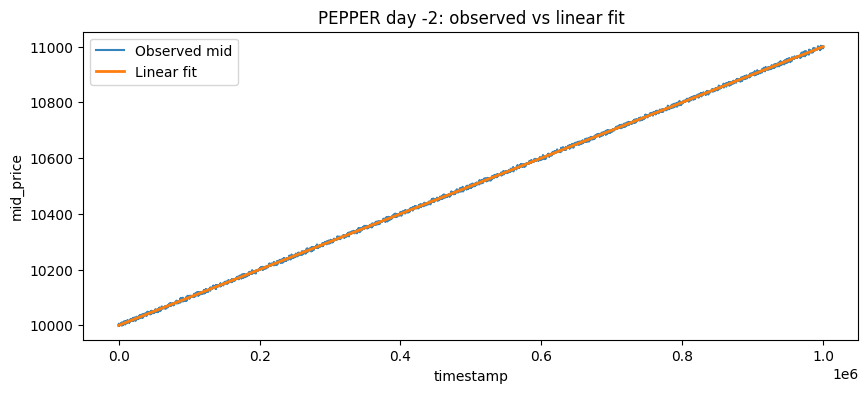

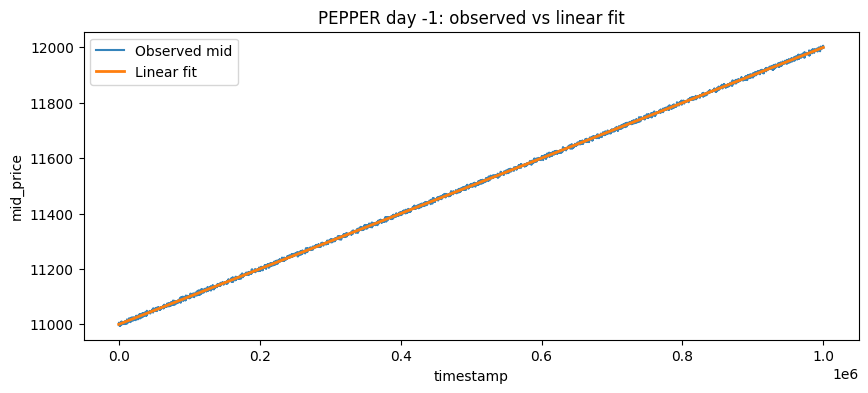

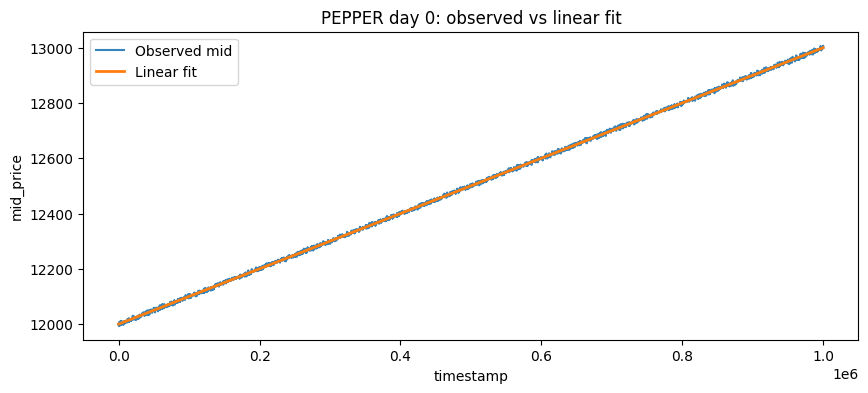

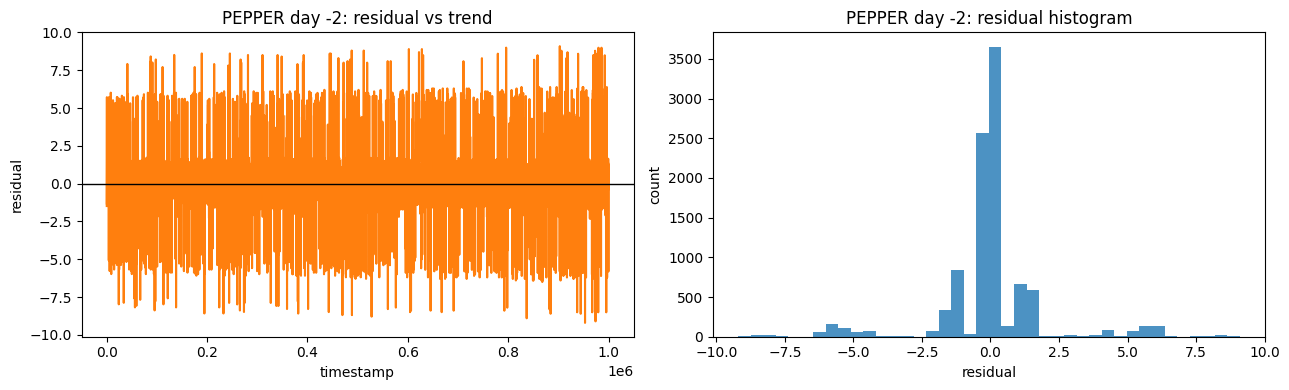

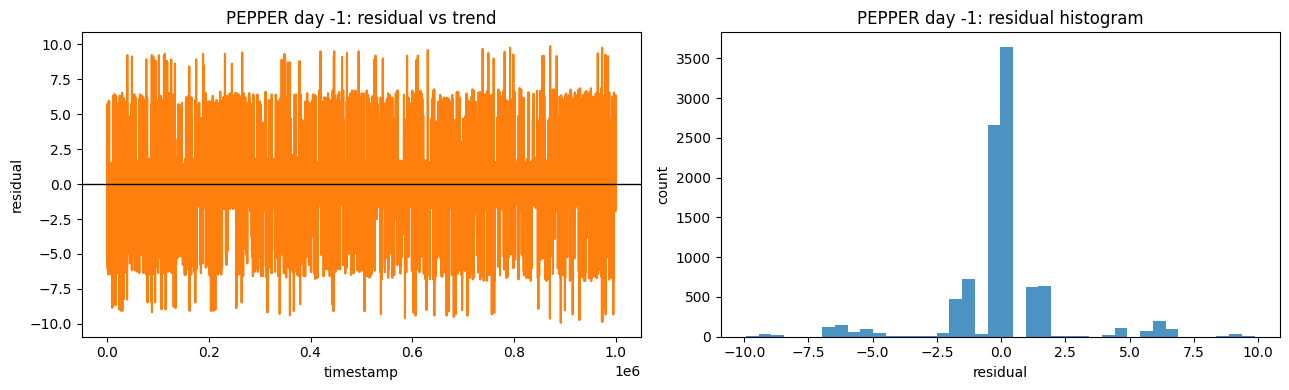

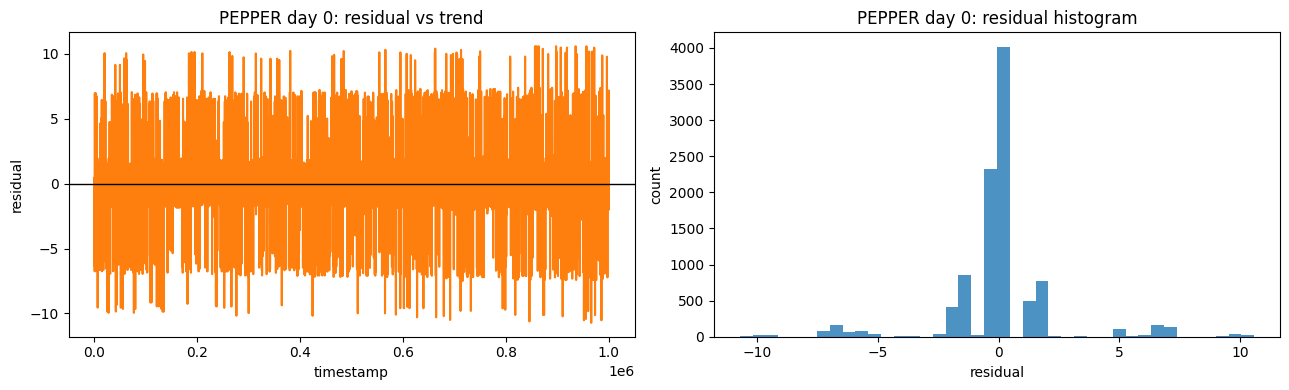

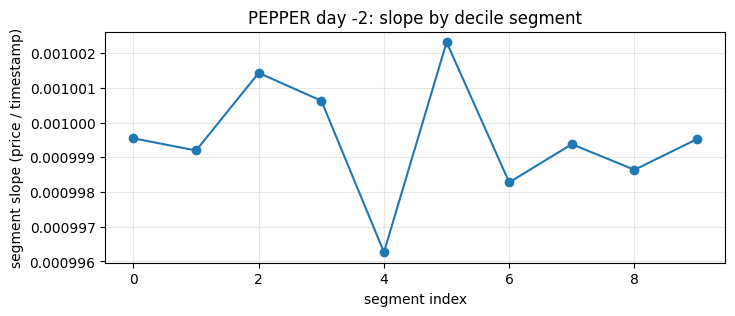

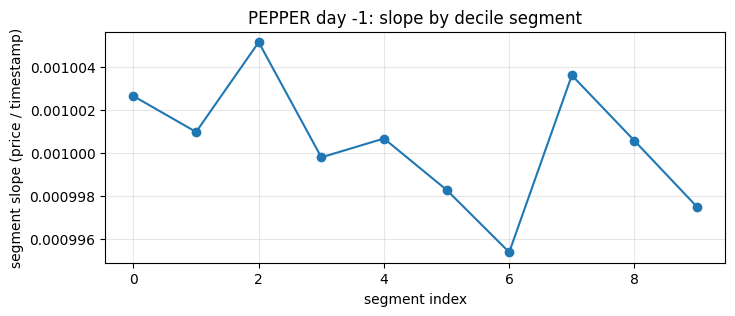

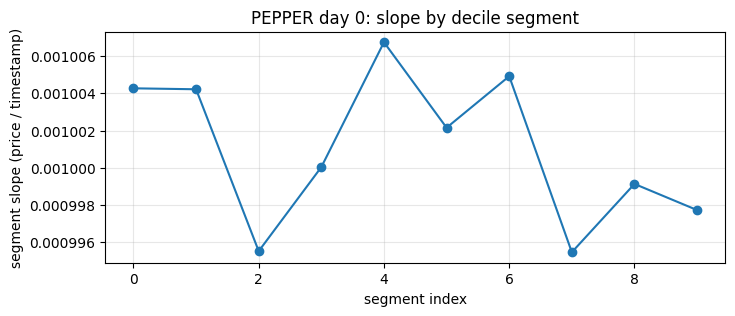

,day,n,start_price,end_price,day_change,slope_price_per_ts,slope_price_per_10k_ts,r2_linear,rmse_resid,resid_std,...,logret_mean,logret_std,logret_autocorr_lag1,segment_slope_mean,segment_slope_std,segment_slope_cv,outlier_2sigma_rate,outlier_3sigma_rate,next_day_open,close_to_next_open_gap
0,-2,9984,9998.5,11001.5,1003.0,0.001,10.000288,0.999952,2.009413,2.009413,...,0.000010,0.000269,-0.495813,0.001000,0.000002,0.001605,0.101562,0.023838,10998.5,-3.0
1,-1,9983,10998.5,11998.0,999.5,0.001,10.000758,0.999941,2.220474,2.220474,...,0.000009,0.000272,-0.495031,0.001000,0.000003,0.002762,0.104578,0.019834,11998.5,0.5
2,0,9979,11998.5,13000.0,1001.5,0.001,10.000793,0.999933,2.359794,2.359794,...,0.000008,0.000266,-0.508609,0.001001,0.000004,0.003823,0.101213,0.024151,NaN,NaN


In [13]:
# Plot: observed price and linear fit per day.
for day in sorted(day_series):
    df_p = day_series[day]
    y_hat = fit_series[day]

    plt.figure(figsize=(10, 4))
    plt.plot(df_p["timestamp"], df_p["mid_price"], label="Observed mid", alpha=0.9)
    plt.plot(df_p["timestamp"], y_hat, label="Linear fit", linewidth=2)
    plt.title(f"PEPPER day {day}: observed vs linear fit")
    plt.xlabel("timestamp")
    plt.ylabel("mid_price")
    plt.legend()
    plt.show()

# Plot: residual path and residual distribution summary.
for day in sorted(resid_series):
    df_p = day_series[day]
    resid = resid_series[day]

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    axes[0].plot(df_p["timestamp"], resid, color="tab:orange")
    axes[0].axhline(0, color="black", linewidth=1)
    axes[0].set_title(f"PEPPER day {day}: residual vs trend")
    axes[0].set_xlabel("timestamp")
    axes[0].set_ylabel("residual")

    axes[1].hist(resid, bins=40, color="tab:blue", alpha=0.8)
    axes[1].set_title(f"PEPPER day {day}: residual histogram")
    axes[1].set_xlabel("residual")
    axes[1].set_ylabel("count")

    plt.tight_layout()
    plt.show()

# Plot: segment slope stability across the day.
if not pepper_segment_df.empty:
    for day in sorted(pepper_segment_df["day"].unique()):
        seg = pepper_segment_df[pepper_segment_df["day"] == day]
        plt.figure(figsize=(8, 3))
        plt.plot(seg["segment"], seg["segment_slope"], marker="o")
        plt.title(f"PEPPER day {day}: slope by decile segment")
        plt.xlabel("segment index")
        plt.ylabel("segment slope (price / timestamp)")
        plt.grid(alpha=0.3)
        plt.show()

pepper_diag_df

In [14]:
key_cols = [
    "day",
    "slope_price_per_10k_ts",
    "r2_linear",
    "rmse_resid",
    "resid_std",
    "resid_abs_q95",
    "positive_step_ratio",
    "step_std",
    "segment_slope_cv",
    "outlier_2sigma_rate",
    "close_to_next_open_gap",
]

pepper_diag_df[key_cols].round(6)

,day,slope_price_per_10k_ts,r2_linear,rmse_resid,resid_std,resid_abs_q95,positive_step_ratio,step_std,segment_slope_cv,outlier_2sigma_rate,close_to_next_open_gap
0,-2,10.000288,0.999952,2.009413,2.009413,5.682915,0.373635,2.823087,0.001605,0.101562,-3.0
1,-1,10.000758,0.999941,2.220474,2.220474,6.187746,0.371669,3.123785,0.002762,0.104578,0.5
2,0,10.000793,0.999933,2.359794,2.359794,6.677369,0.373722,3.332485,0.003823,0.101213,NaN


## PEPPER deeper signal study
Now that linear drift is confirmed, test actionable structure:
- Is there extra edge on pullbacks below trend?
- How stable is local slope over time?
- Is there meaningful curvature beyond a straight line?

In [15]:
horizons = [10, 25, 50, 100]
z_thresholds = [1.0, 1.5, 2.0, 2.5]

event_rows = []
rolling_rows = []
curve_rows = []

for day in sorted(day_series):
    df_p = day_series[day].copy()
    t = df_p["timestamp"].to_numpy(dtype=float)
    y = df_p["mid_price"].to_numpy(dtype=float)
    y_hat = fit_series[day]
    resid = resid_series[day]

    resid_std = float(np.std(resid))
    z = resid / resid_std if resid_std > 1e-12 else np.zeros_like(resid)

    # ---------- Pullback event study ----------
    for thr in z_thresholds:
        hit_idx = np.where(z <= -thr)[0]
        ext_idx = np.where(z >= thr)[0]

        event_row = {
            "day": int(day),
            "z_threshold": thr,
            "n_pullback_events": int(len(hit_idx)),
            "n_extension_events": int(len(ext_idx)),
        }

        for h in horizons:
            valid_pull = hit_idx[hit_idx + h < len(y)]
            valid_ext = ext_idx[ext_idx + h < len(y)]

            if len(valid_pull) > 0:
                pull_rets = (y[valid_pull + h] - y[valid_pull]) / y[valid_pull]
                event_row[f"pull_fwd_ret_{h}"] = float(np.mean(pull_rets))
                event_row[f"pull_pos_rate_{h}"] = float(np.mean(pull_rets > 0))
            else:
                event_row[f"pull_fwd_ret_{h}"] = np.nan
                event_row[f"pull_pos_rate_{h}"] = np.nan

            if len(valid_ext) > 0:
                ext_rets = (y[valid_ext + h] - y[valid_ext]) / y[valid_ext]
                event_row[f"ext_fwd_ret_{h}"] = float(np.mean(ext_rets))
                event_row[f"ext_pos_rate_{h}"] = float(np.mean(ext_rets > 0))
            else:
                event_row[f"ext_fwd_ret_{h}"] = np.nan
                event_row[f"ext_pos_rate_{h}"] = np.nan

        event_rows.append(event_row)

    # ---------- Rolling slope stability ----------
    roll_window = 300
    if len(df_p) > roll_window + 5:
        for i in range(roll_window, len(df_p)):
            t_win = t[i-roll_window:i]
            y_win = y[i-roll_window:i]
            b1, b0 = np.polyfit(t_win, y_win, 1)
            rolling_rows.append({
                "day": int(day),
                "idx": int(i),
                "timestamp": float(t[i]),
                "rolling_slope": float(b1),
            })

    # ---------- Linear vs quadratic fit ----------
    b1, b0 = np.polyfit(t, y, 1)
    y_lin = b1 * t + b0
    ss_tot = float(np.sum((y - np.mean(y)) ** 2))
    ss_res_lin = float(np.sum((y - y_lin) ** 2))
    r2_lin = 1 - ss_res_lin / ss_tot if ss_tot > 0 else np.nan

    q2, q1, q0 = np.polyfit(t, y, 2)
    y_quad = q2 * t**2 + q1 * t + q0
    ss_res_quad = float(np.sum((y - y_quad) ** 2))
    r2_quad = 1 - ss_res_quad / ss_tot if ss_tot > 0 else np.nan

    curve_rows.append({
        "day": int(day),
        "r2_linear": float(r2_lin),
        "r2_quadratic": float(r2_quad),
        "r2_lift_quad_minus_lin": float(r2_quad - r2_lin),
        "quad_coeff": float(q2),
    })

pepper_event_df = pd.DataFrame(event_rows).sort_values(["day", "z_threshold"]).reset_index(drop=True)
pepper_roll_df = pd.DataFrame(rolling_rows)
pepper_curve_df = pd.DataFrame(curve_rows).sort_values("day").reset_index(drop=True)

pepper_event_df.head(12), pepper_curve_df

(    day  z_threshold  n_pullback_events  n_extension_events  pull_fwd_ret_10  \
 0    -2          1.0                584                 550         0.000598   
 1    -2          1.5                533                 527         0.000630   
 2    -2          2.0                515                 499         0.000639   
 3    -2          2.5                384                 402         0.000678   
 4    -1          1.0                578                 570         0.000600   
 5    -1          1.5                541                 558         0.000619   
 6    -1          2.0                520                 524         0.000625   
 7    -1          2.5                381                 414         0.000668   
 8     0          1.0                554                 530         0.000585   
 9     0          1.5                521                 515         0.000602   
 10    0          2.0                503                 507         0.000611   
 11    0          2.5       

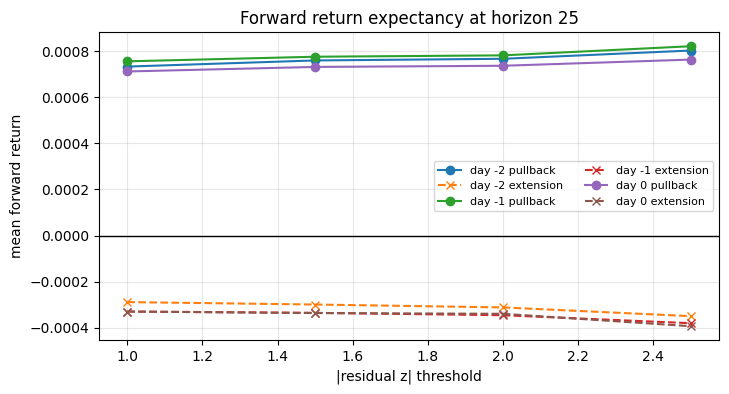

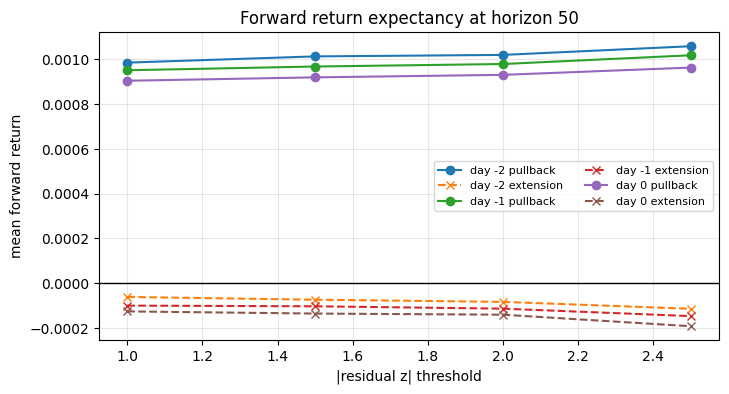

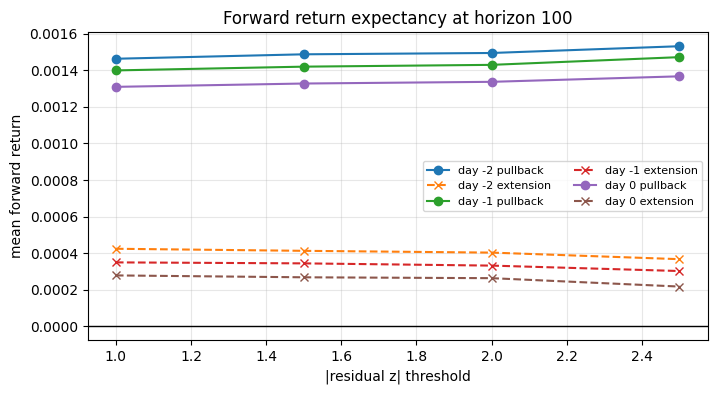

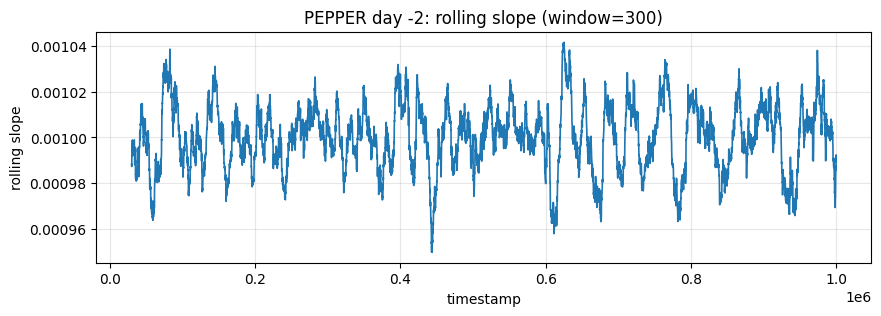

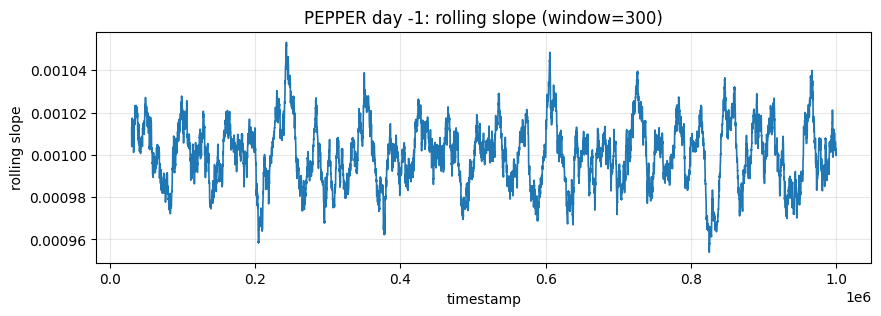

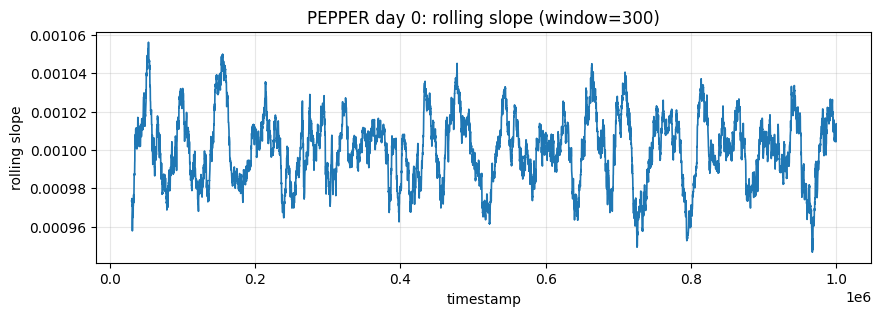

(    day  z_threshold  n_pullback_events  n_extension_events  pull_fwd_ret_50  \
 0    -2          1.0                584                 550         0.000986   
 1    -2          1.5                533                 527         0.001013   
 2    -2          2.0                515                 499         0.001020   
 3    -2          2.5                384                 402         0.001059   
 4    -1          1.0                578                 570         0.000952   
 5    -1          1.5                541                 558         0.000968   
 6    -1          2.0                520                 524         0.000979   
 7    -1          2.5                381                 414         0.001019   
 8     0          1.0                554                 530         0.000905   
 9     0          1.5                521                 515         0.000920   
 10    0          2.0                503                 507         0.000931   
 11    0          2.5       

In [16]:
# Visualize pullback vs extension event expectancy.
for h in [25, 50, 100]:
    plt.figure(figsize=(8, 4))
    for day in sorted(pepper_event_df["day"].unique()):
        sub = pepper_event_df[pepper_event_df["day"] == day]
        plt.plot(sub["z_threshold"], sub[f"pull_fwd_ret_{h}"], marker="o", label=f"day {day} pullback")
        plt.plot(sub["z_threshold"], sub[f"ext_fwd_ret_{h}"], marker="x", linestyle="--", label=f"day {day} extension")
    plt.axhline(0, color="black", linewidth=1)
    plt.title(f"Forward return expectancy at horizon {h}")
    plt.xlabel("|residual z| threshold")
    plt.ylabel("mean forward return")
    plt.legend(ncol=2, fontsize=8)
    plt.grid(alpha=0.3)
    plt.show()

# Visualize rolling slope through time.
if not pepper_roll_df.empty:
    for day in sorted(pepper_roll_df["day"].unique()):
        sub = pepper_roll_df[pepper_roll_df["day"] == day]
        plt.figure(figsize=(10, 3))
        plt.plot(sub["timestamp"], sub["rolling_slope"], linewidth=1.2)
        plt.title(f"PEPPER day {day}: rolling slope (window=300)")
        plt.xlabel("timestamp")
        plt.ylabel("rolling slope")
        plt.grid(alpha=0.3)
        plt.show()

# Compact diagnostic slices for interpretation.
event_focus_cols = [
    "day",
    "z_threshold",
    "n_pullback_events",
    "n_extension_events",
    "pull_fwd_ret_50",
    "pull_pos_rate_50",
    "ext_fwd_ret_50",
    "ext_pos_rate_50",
]

pepper_event_focus = pepper_event_df[event_focus_cols].round(6)
pepper_event_focus, pepper_curve_df.round(8)